In [6]:
import pandas as pd
import seaborn as sns
import folium
import matplotlib.pyplot as plt
from folium.plugins import HeatMap

C:\Users\MichelleDeloyde\AppData\Local\Temp\ipykernel_17912\4265538204.py:1: DtypeWarning: Columns (0: Sheet) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("pre_2025_ttc_bus_delays_cleaned.csv", parse_dates=["Date", "Datetime"])


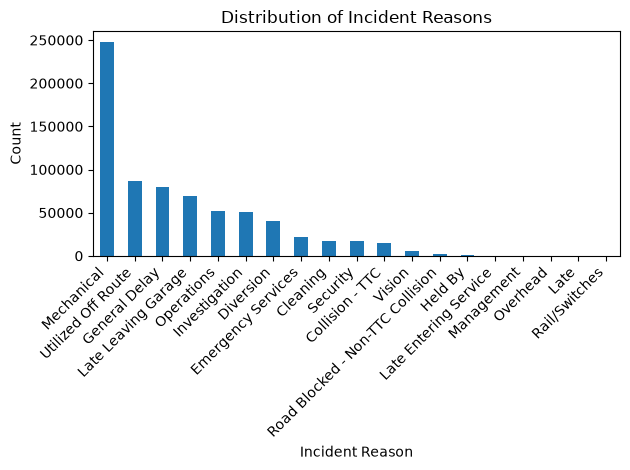

In [7]:
df = pd.read_csv("pre_2025_ttc_bus_delays_cleaned.csv", parse_dates=["Date", "Datetime"])
#create matplotlib plot of all the incident reasons

df["Incident"].value_counts().plot(kind="bar")
plt.xlabel("Incident Reason")
plt.ylabel("Count")
plt.title("Distribution of Incident Reasons")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

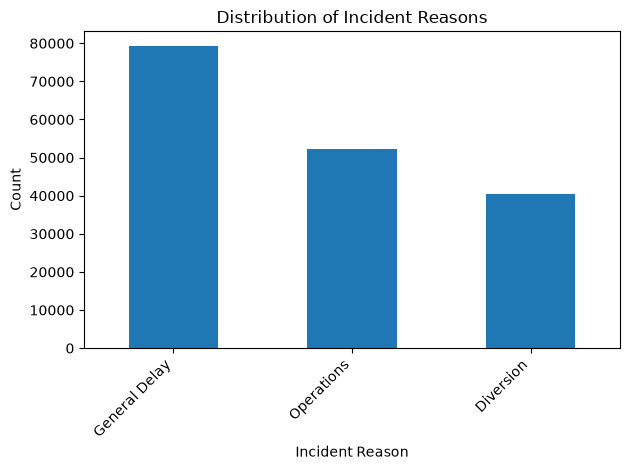

In [8]:
#remove all rows where the incident reason is anything but "Other", "General Delay", "Diversion", "Operations"
df = df[df["Incident"].isin(["Other", "General Delay", "Diversion", "Operations"])]
#plot graph of the incident reasons after removing the other reasons
df["Incident"].value_counts().plot(kind="bar")
plt.xlabel("Incident Reason")
plt.ylabel("Count")
plt.title("Distribution of Incident Reasons")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [9]:
#import "ttc bus delay with coords" csv file
df_coords = pd.read_csv("pre_2025_ttc_bus_delays_with_coords.csv", parse_dates=["Date", "Datetime"])
#create heatmap for "ttc bus delay with coords" with a map showing spatial locations of delays using folium
#81%
#remove all rows where the incident reason is anything but "Other", "General Delay", "Diversion", "Operations"
df_coords = df_coords[df_coords["Incident"].isin(["Other", "General Delay", "Diversion", "Operations"])]
#make it only one random day in 2015
df_coords = df_coords[df_coords["Date"] == df_coords["Date"].sample(n=1).iloc[0]]

toronto_center = [43.70, -79.40]

# Create the base map
heat_map = folium.Map(
    location=toronto_center,
    tiles=None,
    zoom_start=10
)

folium.TileLayer(
    tiles="https://tile.openstreetmap.org/{z}/{x}/{y}.png",
    attr="© OpenStreetMap contributors",
    name="OpenStreetMap",
    referrer_policy="strict-origin"
).add_to(heat_map)

# Prepare incident coordinates as [latitude, longitude]
coords = df_coords[["Latitude", "Longitude"]].apply(
    pd.to_numeric, errors="coerce"
).dropna()

incident_locations = coords[["Latitude", "Longitude"]].values.tolist()

# Add the heat map
HeatMap(
    incident_locations,
    radius=15
).add_to(heat_map)

heat_map

C:\Users\MichelleDeloyde\AppData\Local\Temp\ipykernel_17912\3161237567.py:2: DtypeWarning: Columns (0: Sheet) have mixed types. Specify dtype option on import or set low_memory=False.
  df_coords = pd.read_csv("pre_2025_ttc_bus_delays_with_coords.csv", parse_dates=["Date", "Datetime"])
